
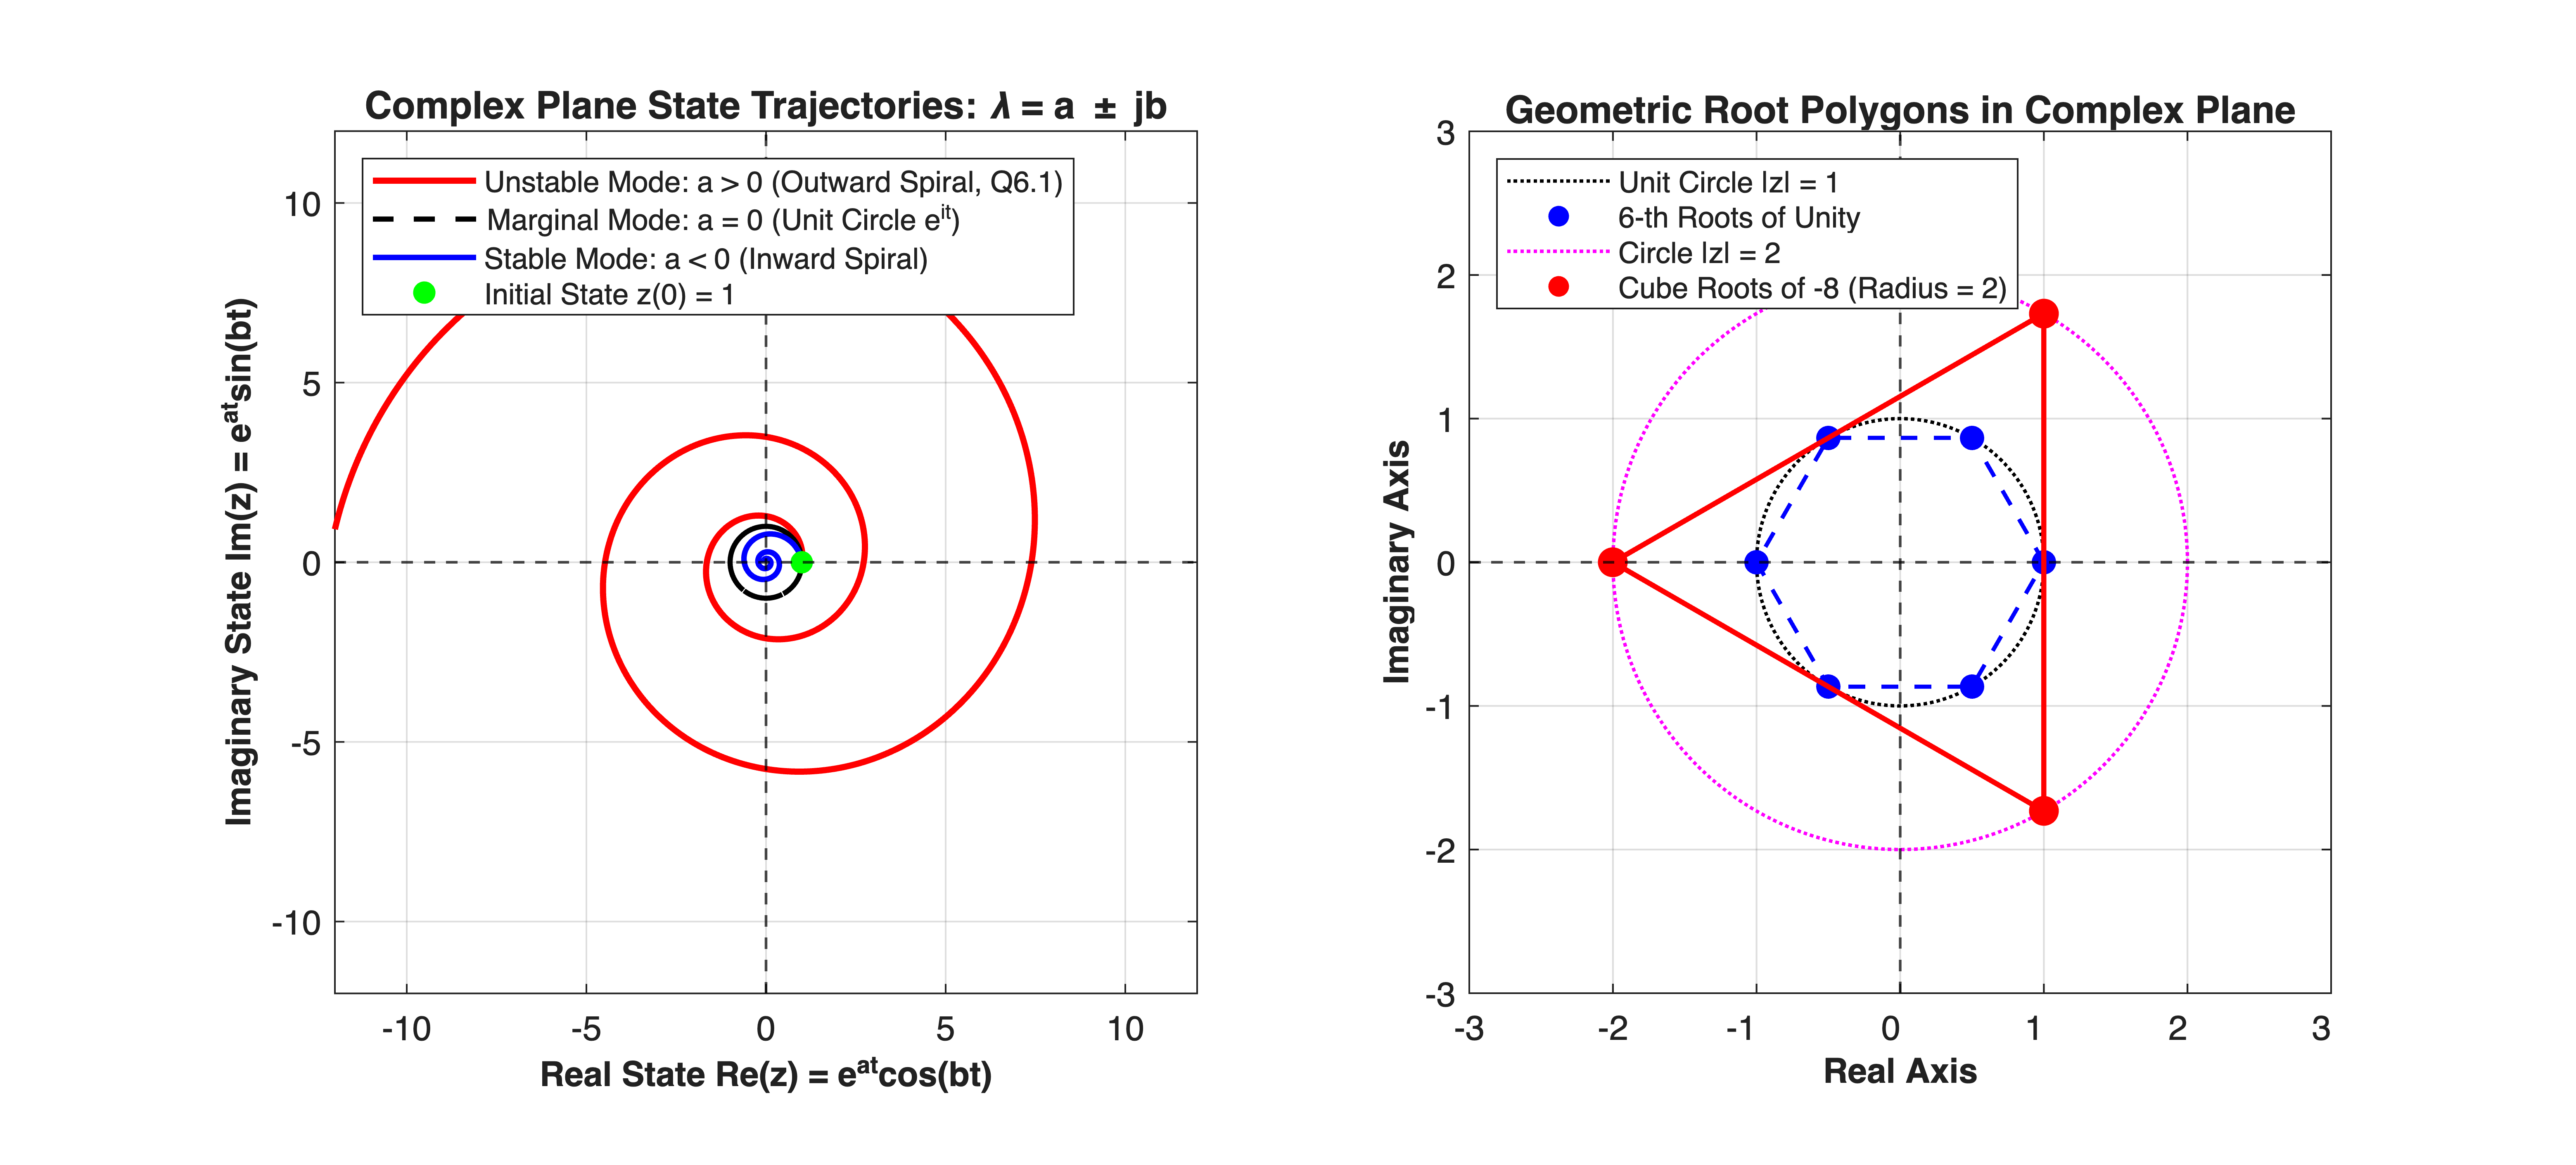

In [1]:
%% MIT 18.03 Lecture 6: Complex Exponential, Phase Spiral & Root Geometry
% Description: Visualizes the dynamic evolution of complex state trajectories:
%              1) Complex exponential spirals: z(t) = exp((a + i*b)*t) for a > 0, a = 0, a < 0.
%              2) Geometry of polynomial roots: n-th roots of unity and cube roots of -8.
%
% % Required Toolboxes:
% %   - Base MATLAB (Core execution)
% %   - Control System Toolbox (Optional: for LTI state-space pole comparisons)
%
% % MBD Concept Mapping: Demonstrates continuous-time dynamic modes from eigenvalue
% %                      lambda = a + j*b. The real part a governs envelope growth/decay,
% %                      while the imaginary part b dictates rotational oscillation frequency.


clear; clc; close all;


%% =========================================================================
%% Part 1: Continuous Complex Exponential Trajectories (Lecture Section [2])
%% =========================================================================
t = linspace(0, 2.5, 1000);
b_freq = 2 * pi; % Oscillation frequency (1 Hz, 2*pi rad/s)


% Three dynamic cases: Unstable (Lecture Q6.1), Undamped / Center, Stable
lambda_unstable =  1.0 + 1i * b_freq; % a > 0: Outward expanding spiral
lambda_marginal =  0.0 + 1i * b_freq; % a = 0: Pure circle (Euler's identity)
lambda_stable   = -1.0 + 1i * b_freq; % a < 0: Inward decaying spiral


z_unstable = exp(lambda_unstable * t);
z_marginal = exp(lambda_marginal * t);
z_stable   = exp(lambda_stable * t);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Complex Phase Plane Trajectories
subplot(1, 2, 1);
hold on; grid on; box on;


% Reference origin axes
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


plot(real(z_unstable), imag(z_unstable), 'r-', 'LineWidth', 1.8, ...
     'DisplayName', 'Unstable Mode: a > 0 (Outward Spiral, Q6.1)');
plot(real(z_marginal), imag(z_marginal), 'k--', 'LineWidth', 1.5, ...
     'DisplayName', 'Marginal Mode: a = 0 (Unit Circle e^{it})');
plot(real(z_stable), imag(z_stable), 'b-', 'LineWidth', 1.6, ...
     'DisplayName', 'Stable Mode: a < 0 (Inward Spiral)');


% Starting point markers
plot(1, 0, 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 6, 'DisplayName', 'Initial State z(0) = 1');


axis equal;
xlim([-12, 12]);
ylim([-12, 12]);
xlabel('Real State Re(z) = e^{at}cos(bt)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary State Im(z) = e^{at}sin(bt)', 'FontSize', 10, 'FontWeight', 'bold');
title('Complex Plane State Trajectories: \lambda = a \pm jb', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);


%% =========================================================================
%% Part 2: Geometric Roots of Unity and Cube Roots of -8 (Lecture Section [1])
%% =========================================================================
subplot(1, 2, 2);
hold on; grid on; box on;


xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% 1. Sixth Roots of Unity (Dividing unit circle into 6 pieces)
n_unity = 6;
k_unity = 0:(n_unity - 1);
roots_unity = exp(1i * (2 * pi * k_unity / n_unity));


theta_circle = linspace(0, 2*pi, 200);
plot(cos(theta_circle), sin(theta_circle), 'k:', 'LineWidth', 1.0, ...
     'DisplayName', 'Unit Circle |z| = 1');
plot([real(roots_unity), real(roots_unity(1))], [imag(roots_unity), imag(roots_unity(1))], ...
     'b--', 'LineWidth', 1.2, 'HandleVisibility', 'off');
scatter(real(roots_unity), imag(roots_unity), 50, 'b', 'filled', ...
        'DisplayName', '6-th Roots of Unity');


% 2. Cube Roots of -8: |z| = 2, arguments = pi/3, pi, 5pi/3
radius_8 = 2;
theta_cube = [pi/3, pi, 5*pi/3];
roots_cube_8 = radius_8 * exp(1i * theta_cube);


plot(radius_8 * cos(theta_circle), radius_8 * sin(theta_circle), 'm:', 'LineWidth', 1.0, ...
     'DisplayName', 'Circle |z| = 2');
plot([real(roots_cube_8), real(roots_cube_8(1))], [imag(roots_cube_8), imag(roots_cube_8(1))], ...
     'r-', 'LineWidth', 1.5, 'HandleVisibility', 'off');
scatter(real(roots_cube_8), imag(roots_cube_8), 75, 'r', 'filled', ...
        'DisplayName', 'Cube Roots of -8 (Radius = 2)');


axis equal;
xlim([-3, 3]);
ylim([-3, 3]);
xlabel('Real Axis', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis', 'FontSize', 10, 'FontWeight', 'bold');
title('Geometric Root Polygons in Complex Plane', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);

In [2]:


fprintf('=== Complex Exponential Trajectory Metrics ===\n');

=== Complex Exponential Trajectory Metrics ===

In [3]:
fprintf('Unstable Pole : a = %+.2f, b = %.2f rad/s -> Escape amplitude at t=1: %.4f\n', ...
        real(lambda_unstable), imag(lambda_unstable), abs(exp(lambda_unstable * 1)));

Unstable Pole : a = +1.00, b = 6.28 rad/s -> Escape amplitude at t=1: 2.7183

In [4]:
fprintf('Stable Pole   : a = %+.2f, b = %.2f rad/s -> Decay amplitude at t=1 : %.4f\n', ...
        real(lambda_stable), imag(lambda_stable), abs(exp(lambda_stable * 1)));

Stable Pole   : a = -1.00, b = 6.28 rad/s -> Decay amplitude at t=1 : 0.3679

In [5]:
fprintf('Cube Roots of -8: 1 + sqrt(3)i, -2, 1 - sqrt(3)i\n');

Cube Roots of -8: 1 + sqrt(3)i, -2, 1 - sqrt(3)i

In [6]:
fprintf('==============================================\n');